# One receptor working as a sensor

This notebook deliberately ignores where the experimental signal comes from. It uses one simple chain:

$$
\text{target concentration} \longrightarrow \text{receptor occupancy} \longrightarrow \text{signal}
$$

It then treats the simulated measurements exactly like an analytical calibration to calculate:

- sensitivity (calibration slope)
- linear range and $R^2$
- instrument-limited and noise-limited resolution
- LOD and LOQ
- the central design objective: minimize concentration-equivalent uncertainty $\sigma_Y/|S|$

All teaching figures are exported as **separate files**.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, brentq
from scipy.stats import norm, chi2, t

BLACK = "#1F2A2E"
GREY = "#65747B"
LIGHT_GREY = "#DCE6E8"
ROYAL_BLUE = "#304894"
HABANERO_ORANGE = "#F47C20"
POWDER_BLUE = "#93A9D8"
WARM_SAND = "#D8A071"
MUTED_PLUM = "#69577F"
MUTED_CORAL = "#C96855"

plt.rcParams.update({
    "font.size": 11,
    "axes.labelcolor": BLACK,
    "axes.titlecolor": BLACK,
    "text.color": BLACK,
    "xtick.color": BLACK,
    "ytick.color": BLACK,
    "axes.edgecolor": BLACK,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

## 0. Inputs — edit only this cell

In [2]:
# --------------------------- RECEPTOR INPUTS ---------------------------
KD_NM = 100.0
DEMO_CONCENTRATION_NM = 1.0

# ---------------------------- SIGNAL INPUTS ----------------------------
# Unbound receptor signal.
BASELINE_SIGNAL_AU = 50.0

# G = (fully bound signal - unbound signal) / unbound signal x 100%.
# Therefore G = 300% means fully bound signal = 4 x unbound signal.
FULL_OCCUPANCY_SIGNAL_CHANGE_PERCENT = 300.0

# -------------------------- CALIBRATION INPUTS -------------------------
CALIBRATION_CONCENTRATIONS_NM = np.array([
    0.0, 0.10, 0.25, 0.50, 1.0, 2.0, 4.0, 6.0, 8.0, 10.0, 15.0, 20.0
])

# Expected SD at each calibration level, in the same order as the concentrations.
# The first value is ignored because zero-concentration noise is obtained from
# the processed blank experiment below. Different values demonstrate that every
# nonzero calibration point can have a different level of noise.
CALIBRATION_NOISE_SD_AU = np.array([
    np.nan, 0.150, 0.151, 0.152, 0.159, 0.182,
    0.252, 0.333, 0.417, 0.500, 0.701, 0.888
])

LINEAR_RANGE_MAX_NM = 10.0
REPLICATES_PER_LEVEL = 5
RANDOM_SEED = 17
USE_WEIGHTED_REGRESSION = True

# Confidence interval shown for each estimated replicate SD. With only five
# replicates, the interval is intentionally broad because the SD estimate is
# itself uncertain.
NOISE_SD_CONFIDENCE_LEVEL = 0.95

# Nonzero levels up to this concentration are used to estimate low-level noise.
LOW_LEVEL_PRECISION_MAX_NM = 2.0

# Teaching checks for the selected linear range. R squared is not used alone.
MIN_R_SQUARED = 0.995
MAX_RESIDUAL_PERCENT_OF_RESPONSE_SPAN = 5.0

# ---------------------------- BLANK INPUTS -----------------------------
# Recommended: calculate noise from the final processed response
# Y = 100 x (I_after - I_before) / I_before for each target-free experiment.
# Use "direct_signal" only when the reported calibration variable is the direct
# signal itself rather than a paired normalized response.
BLANK_NOISE_MODE = "paired_processed_response"  # or "direct_signal"

BLANK_BEFORE_AU = np.array([
    50.0, 50.1, 49.9, 50.2, 49.8,
    50.1, 50.0, 49.9, 50.2, 49.8
])
BLANK_AFTER_AU = np.array([
    50.1000, 49.8996, 49.9000, 50.4008, 49.7004,
    49.8996, 50.1000, 49.9000, 50.0996, 49.9992
])

# Alternative direct-signal blank series used only when
# BLANK_NOISE_MODE = "direct_signal".
DIRECT_BLANK_SIGNALS_AU = np.array([
    50.0, 50.1, 49.9, 50.2, 49.8,
    50.1, 50.0, 49.9, 50.2, 49.8
])

# Documentation only: choose the population that matches the real product.
# Examples: "same sensor over time" or "fresh disposable sensors across batches".
BLANK_POPULATION_DESCRIPTION = "same sensor over the intended assay timescale"

# Smallest signal increment displayed by the instrument. Reduce this value to
# model an instrument with finer digital resolution.
INSTRUMENT_SIGNAL_STEP_AU = 0.10

# These factors define calculation criteria; changing them does not physically
# improve the sensor. Change LOD_FACTOR to 3.3 if required by your method.
RESOLUTION_NOISE_FACTOR = 2.0
LOD_FACTOR = 3.0
LOQ_FACTOR = 10.0

# Formal detection-probability inputs. The default is a 95/95 criterion:
# 5% false-positive probability and 5% false-negative probability.
FALSE_POSITIVE_RATE = 0.05
FALSE_NEGATIVE_RATE = 0.05

# Precision-only LOQ demonstration. A real LOQ must also pass accuracy/recovery.
LOQ_MAX_RELATIVE_SD = 0.10

# ---------------- ELECTRONIC-NOISE BUDGET EXAMPLE --------------------
# These are editable teaching values, not specifications for a particular
# potentiostat. All four contributions are converted to input-referred rms
# current before they are compared.
TEMPERATURE_K = 298.15
EFFECTIVE_NOISE_BANDWIDTH_HZ = 10.0
FEEDBACK_RESISTANCE_OHM = 1.0e6
MEAN_FARADAIC_CURRENT_A = 1.0e-6

OPAMP_CURRENT_NOISE_DENSITY_A_PER_SQRT_HZ = 2.0e-15
OPAMP_VOLTAGE_NOISE_DENSITY_V_PER_SQRT_HZ = 8.0e-9
DOUBLE_LAYER_CAPACITANCE_F = 10.0e-9
CHARACTERISTIC_FREQUENCY_HZ = 100.0
# Separate upper edge for the alternative broadband capacitive-noise integral.
# This is not assumed to equal the effective noise bandwidth in a real filter.
CAPACITIVE_INTEGRATION_UPPER_HZ = 10.0

ADC_FULL_SCALE_CURRENT_SPAN_A = 2.0e-6
ADC_EFFECTIVE_BITS = 18

# --------------- BANDWIDTH / AVERAGING TEACHING EXAMPLE --------------
# These values are illustrative and are not measured sensor specifications.
# White noise is specified at one reference averaging time. Linear drift is
# treated as a deterministic bias relative to the midpoint of the window.
AVERAGING_REFERENCE_TIME_S = 0.10
WHITE_SD_AT_REFERENCE_TIME_PERCENT = 1.0
LINEAR_DRIFT_RATE_PERCENT_PER_MIN = 0.10
SIGNAL_CHARACTERISTIC_FREQUENCY_HZ = 0.10
AVERAGING_TIME_MIN_S = 0.01
AVERAGING_TIME_MAX_S = 300.0

# ----------------------------- FILE OUTPUT -----------------------------
SAVE_FIGURES = True
FIGURE_DPI = 220

# Keep exports beside this tutorial even when Jupyter was launched from the
# parent project directory. If the notebook is moved elsewhere, the current
# directory remains the fallback.
TUTORIAL_DIRECTORY = next(
    (
        candidate
        for candidate in (Path.cwd(), Path.cwd() / "noise_tutorial")
        if (candidate / "simple_receptor_sensor_lod_loq.ipynb").exists()
    ),
    Path.cwd(),
)
FIGURE_DIRECTORY = TUTORIAL_DIRECTORY / "figures"

## 1. Receptor model and signal model

For a 1:1 receptor under the free-target approximation:

$$
\theta=\frac{C}{K_D+C}
$$

The signal is defined only as a teaching transducer:

$$
I=I_U\left(1+\theta G\right)
$$

Here, $G$ is used as a fraction in the equation. For example, $300\%=3$.

In [3]:
if KD_NM <= 0:
    raise ValueError("KD_NM must be positive.")
if BASELINE_SIGNAL_AU <= 0:
    raise ValueError("BASELINE_SIGNAL_AU must be positive.")
if INSTRUMENT_SIGNAL_STEP_AU <= 0:
    raise ValueError("INSTRUMENT_SIGNAL_STEP_AU must be positive.")
if LINEAR_RANGE_MAX_NM <= 0:
    raise ValueError("LINEAR_RANGE_MAX_NM must be positive.")
if len(CALIBRATION_CONCENTRATIONS_NM) != len(CALIBRATION_NOISE_SD_AU):
    raise ValueError("CALIBRATION_CONCENTRATIONS_NM and CALIBRATION_NOISE_SD_AU must have equal length.")
if np.any(CALIBRATION_NOISE_SD_AU[CALIBRATION_CONCENTRATIONS_NM > 0] <= 0):
    raise ValueError("Every nonzero calibration level must have a positive noise SD.")
if LOW_LEVEL_PRECISION_MAX_NM <= 0:
    raise ValueError("LOW_LEVEL_PRECISION_MAX_NM must be positive.")
if not (0 < NOISE_SD_CONFIDENCE_LEVEL < 1):
    raise ValueError("NOISE_SD_CONFIDENCE_LEVEL must lie between 0 and 1.")
if BLANK_NOISE_MODE not in {"paired_processed_response", "direct_signal"}:
    raise ValueError("BLANK_NOISE_MODE must be paired_processed_response or direct_signal.")
if len(BLANK_BEFORE_AU) != len(BLANK_AFTER_AU):
    raise ValueError("BLANK_BEFORE_AU and BLANK_AFTER_AU must have equal length.")
if len(BLANK_BEFORE_AU) < 3:
    raise ValueError("At least three paired blank experiments are required for this demonstration.")
if np.any(BLANK_BEFORE_AU <= 0):
    raise ValueError("Paired blank before-signals must be positive.")
if not (0 < FALSE_POSITIVE_RATE < 0.5):
    raise ValueError("FALSE_POSITIVE_RATE must lie between 0 and 0.5.")
if not (0 < FALSE_NEGATIVE_RATE < 0.5):
    raise ValueError("FALSE_NEGATIVE_RATE must lie between 0 and 0.5.")
if not (0 < LOQ_MAX_RELATIVE_SD < 1):
    raise ValueError("LOQ_MAX_RELATIVE_SD must lie between 0 and 1.")
if TEMPERATURE_K <= 0 or EFFECTIVE_NOISE_BANDWIDTH_HZ <= 0:
    raise ValueError("Temperature and effective noise bandwidth must be positive.")
if FEEDBACK_RESISTANCE_OHM <= 0:
    raise ValueError("FEEDBACK_RESISTANCE_OHM must be positive.")
if MEAN_FARADAIC_CURRENT_A < 0:
    raise ValueError("MEAN_FARADAIC_CURRENT_A cannot be negative.")
if OPAMP_CURRENT_NOISE_DENSITY_A_PER_SQRT_HZ < 0:
    raise ValueError("Op-amp current-noise density cannot be negative.")
if OPAMP_VOLTAGE_NOISE_DENSITY_V_PER_SQRT_HZ < 0:
    raise ValueError("Op-amp voltage-noise density cannot be negative.")
if DOUBLE_LAYER_CAPACITANCE_F < 0 or CHARACTERISTIC_FREQUENCY_HZ < 0:
    raise ValueError("Capacitance and characteristic frequency cannot be negative.")
if CAPACITIVE_INTEGRATION_UPPER_HZ <= 0:
    raise ValueError("Capacitive integration upper frequency must be positive.")
if ADC_FULL_SCALE_CURRENT_SPAN_A <= 0 or ADC_EFFECTIVE_BITS <= 0:
    raise ValueError("ADC span and effective bit count must be positive.")
if AVERAGING_REFERENCE_TIME_S <= 0:
    raise ValueError("AVERAGING_REFERENCE_TIME_S must be positive.")
if WHITE_SD_AT_REFERENCE_TIME_PERCENT <= 0:
    raise ValueError("WHITE_SD_AT_REFERENCE_TIME_PERCENT must be positive.")
if LINEAR_DRIFT_RATE_PERCENT_PER_MIN < 0:
    raise ValueError("LINEAR_DRIFT_RATE_PERCENT_PER_MIN cannot be negative.")
if SIGNAL_CHARACTERISTIC_FREQUENCY_HZ <= 0:
    raise ValueError("SIGNAL_CHARACTERISTIC_FREQUENCY_HZ must be positive.")
if not (0 < AVERAGING_TIME_MIN_S < AVERAGING_TIME_MAX_S):
    raise ValueError("Averaging-time limits must be positive and ordered.")

G = FULL_OCCUPANCY_SIGNAL_CHANGE_PERCENT / 100.0
BOUND_TO_UNBOUND_SIGNAL_RATIO = 1.0 + G

def occupancy(concentration_nM):
    concentration_nM = np.asarray(concentration_nM, dtype=float)
    return concentration_nM / (KD_NM + concentration_nM)

def ideal_signal(concentration_nM):
    return BASELINE_SIGNAL_AU * (1.0 + G * occupancy(concentration_nM))

theta_demo = float(occupancy(DEMO_CONCENTRATION_NM))
signal_demo = float(ideal_signal(DEMO_CONCENTRATION_NM))
signal_change_demo_percent = theta_demo * FULL_OCCUPANCY_SIGNAL_CHANGE_PERCENT

demo = pd.Series({
    "Kd (nM)": KD_NM,
    "demonstration concentration (nM)": DEMO_CONCENTRATION_NM,
    "receptor occupancy (%)": 100 * theta_demo,
    "fully bound / unbound signal ratio": BOUND_TO_UNBOUND_SIGNAL_RATIO,
    "predicted total signal (a.u.)": signal_demo,
    "predicted signal change (%)": signal_change_demo_percent,
})
demo.round(4)

Kd (nM)                               100.0000
demonstration concentration (nM)        1.0000
receptor occupancy (%)                  0.9901
fully bound / unbound signal ratio      4.0000
predicted total signal (a.u.)          51.4851
predicted signal change (%)             2.9703
dtype: float64

**Important interpretation:** a maximum change of 300% does not mean that every target concentration produces a 300% change. It means 300% only at 100% occupancy. The measured change is $\theta\times300\%$.

## 2. Separate Figure 1 — receptor occupancy

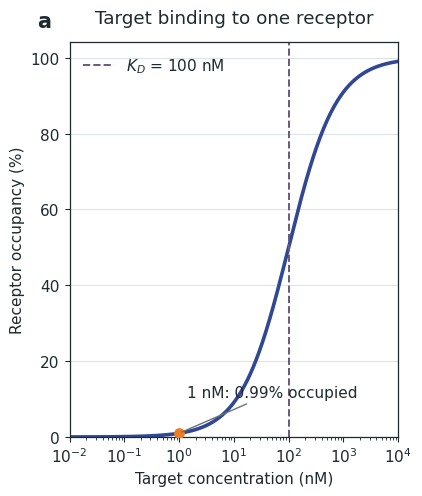

In [4]:
def journal_axes(title, panel_letter):
    fig, ax = plt.subplots(figsize=(4.35, 5.10))
    ax.set_title(title, pad=14)
    ax.text(-0.10, 1.08, panel_letter, transform=ax.transAxes,
            fontsize=15, fontweight="bold", va="top")
    ax.grid(axis="y", color=LIGHT_GREY, linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(0.9)
        spine.set_color(BLACK)
    return fig, ax

plot_c = np.logspace(-2, 4, 600)
fig1, ax1 = journal_axes("Target binding to one receptor", "a")
ax1.plot(plot_c, 100 * occupancy(plot_c), color=ROYAL_BLUE, linewidth=2.6)
ax1.axvline(KD_NM, color=MUTED_PLUM, linestyle="--", linewidth=1.4,
            label=fr"$K_D$ = {KD_NM:g} nM")
ax1.scatter([DEMO_CONCENTRATION_NM], [100 * theta_demo],
            color=HABANERO_ORANGE, s=45, zorder=3)
ax1.annotate(
    f"{DEMO_CONCENTRATION_NM:g} nM: {100*theta_demo:.2f}% occupied",
    xy=(DEMO_CONCENTRATION_NM, 100 * theta_demo),
    xytext=(6, 26), textcoords="offset points",
    arrowprops={"arrowstyle": "-", "color": GREY}, color=BLACK,
)
ax1.set_xscale("log")
ax1.set_xlim(plot_c.min(), plot_c.max())
ax1.set_ylim(0, 104)
ax1.set_xlabel("Target concentration (nM)")
ax1.set_ylabel("Receptor occupancy (%)")
ax1.legend(frameon=False, loc="upper left")
fig1.tight_layout()

if SAVE_FIGURES:
    FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)
    fig1.savefig(FIGURE_DIRECTORY / "01_receptor_occupancy.png", dpi=FIGURE_DPI,
                 bbox_inches="tight", facecolor="white")
    fig1.savefig(FIGURE_DIRECTORY / "01_receptor_occupancy.svg",
                 bbox_inches="tight", facecolor="white")
plt.show()

## 2b. Additional figure — affinity shifts the occupancy curve

Changing $K_D$ translates an ideal 1:1 binding curve along the concentration axis. It does not change the normalized 10–90% occupancy window: $C_{10}=K_D/9$ and $C_{90}=9K_D$, an 81-fold concentration ratio. This occupancy convention is not an experimental LOD or automatically the analytical linear range.

/var/folders/3q/_6t86x4d3816pk4n9zt66l100000gn/T/ipykernel_34590/3567614619.py:93: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig_kd.tight_layout()


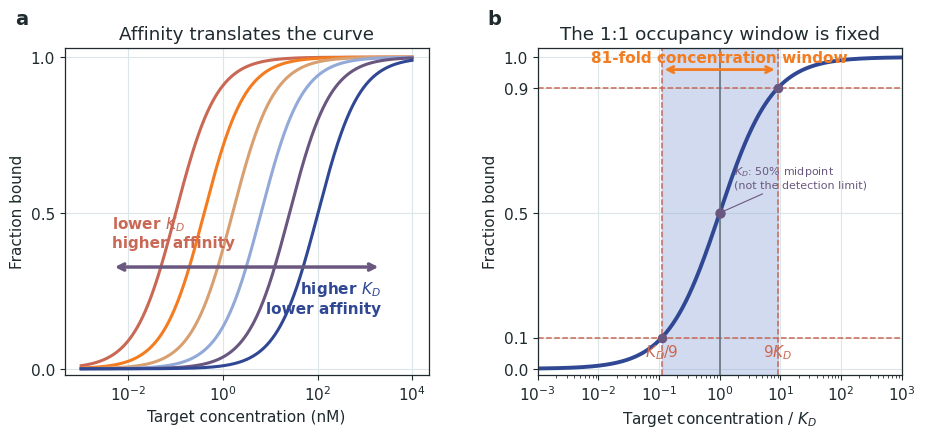

In [5]:
def panel_label(ax, label):
    ax.text(-0.10, 1.06, label, transform=ax.transAxes,
            fontsize=14, fontweight="bold", ha="right", va="bottom")

def finish_axis(ax, grid_axis="both"):
    ax.grid(True, which="major", axis=grid_axis,
            color=LIGHT_GREY, linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_color(BLACK)
        spine.set_linewidth(0.9)

def save_figure(fig, filename):
    if SAVE_FIGURES:
        FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIRECTORY / f"{filename}.png", dpi=FIGURE_DPI,
                    bbox_inches="tight", facecolor="white")
        fig.savefig(FIGURE_DIRECTORY / f"{filename}.svg",
                    bbox_inches="tight", facecolor="white")

concentration_nM = np.logspace(-3, 4, 900)
kd_family_nM = np.array([0.10, 0.40, 1.6, 6.4, 25.6, 102.4])
kd_family_colors = [
    MUTED_CORAL, HABANERO_ORANGE, WARM_SAND,
    POWDER_BLUE, MUTED_PLUM, ROYAL_BLUE,
]

normalized_concentration = np.logspace(-3, 3, 900)
normalized_occupancy = normalized_concentration / (1.0 + normalized_concentration)
c10_over_kd = 1.0 / 9.0
c90_over_kd = 9.0

fig_kd, axes_kd = plt.subplots(
    1, 2, figsize=(10.8, 4.25), gridspec_kw={"wspace": 0.30}
)

ax = axes_kd[0]
for kd_nM, color in zip(kd_family_nM, kd_family_colors):
    occupancy_values = concentration_nM / (kd_nM + concentration_nM)
    ax.semilogx(concentration_nM, occupancy_values, color=color, lw=2.2)
ax.annotate(
    "", xy=(0.13, 0.33), xytext=(0.87, 0.33), xycoords="axes fraction",
    arrowprops={"arrowstyle": "<->", "lw": 2.5, "color": MUTED_PLUM},
)
ax.text(0.13, 0.39, "lower $K_D$\nhigher affinity",
        transform=ax.transAxes, ha="left", color=MUTED_CORAL,
        fontweight="bold")
ax.text(0.87, 0.19, "higher $K_D$\nlower affinity",
        transform=ax.transAxes, ha="right", color=ROYAL_BLUE,
        fontweight="bold")
ax.set(xlabel="Target concentration (nM)", ylabel="Fraction bound",
       ylim=(-0.02, 1.03), title="Affinity translates the curve")
ax.set_yticks([0, 0.5, 1.0])
panel_label(ax, "a")
finish_axis(ax, "both")

ax = axes_kd[1]
ax.semilogx(normalized_concentration, normalized_occupancy,
            color=ROYAL_BLUE, lw=2.8)
ax.axvspan(c10_over_kd, c90_over_kd, color=POWDER_BLUE, alpha=0.42,
           label="10–90% occupancy")
for occupancy_level, concentration_ratio in (
    (0.1, c10_over_kd), (0.9, c90_over_kd)
):
    ax.axhline(occupancy_level, color=MUTED_CORAL, lw=1.1, ls="--")
    ax.axvline(concentration_ratio, color=MUTED_CORAL, lw=1.1, ls="--")
    ax.scatter([concentration_ratio], [occupancy_level],
               color=MUTED_PLUM, s=35, zorder=4)
ax.axvline(1.0, color=GREY, lw=1.2)
ax.scatter([1.0], [0.5], color=MUTED_PLUM, s=42, zorder=5)
ax.annotate(
    "", xy=(c90_over_kd, 0.96), xytext=(c10_over_kd, 0.96),
    arrowprops={"arrowstyle": "<->", "lw": 2.0, "color": HABANERO_ORANGE},
)
ax.text(1.0, 0.975, "81-fold concentration window",
        ha="center", va="bottom", color=HABANERO_ORANGE,
        fontweight="bold")
ax.text(c10_over_kd, 0.04, r"$K_D/9$", ha="center", color=MUTED_CORAL)
ax.annotate(
    "$K_D$: 50% midpoint\n(not the detection limit)", (1.0, 0.5),
    xytext=(10, 18), textcoords="offset points", ha="left",
    color=MUTED_PLUM, fontsize=8,
    arrowprops={"arrowstyle": "-", "lw": 0.8, "color": MUTED_PLUM},
)
ax.text(c90_over_kd, 0.04, r"$9K_D$", ha="center", color=MUTED_CORAL)
ax.set(xlim=(1e-3, 1e3), ylim=(-0.02, 1.03),
       xlabel=r"Target concentration / $K_D$", ylabel="Fraction bound",
       title="The 1:1 occupancy window is fixed")
ax.set_yticks([0, 0.1, 0.5, 0.9, 1.0])
panel_label(ax, "b")
finish_axis(ax, "both")

fig_kd.tight_layout()
save_figure(fig_kd, "00b_kd_useful_dynamic_range")
plt.show()

## 3. Separate Figure 2 — occupancy becomes signal

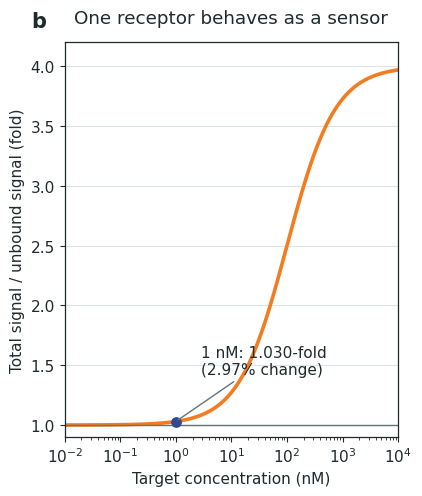

In [6]:
fig2, ax2 = journal_axes("One receptor behaves as a sensor", "b")
ax2.plot(plot_c, ideal_signal(plot_c) / BASELINE_SIGNAL_AU,
         color=HABANERO_ORANGE, linewidth=2.6)
ax2.axhline(1.0, color=GREY, linewidth=1.0)
ax2.scatter([DEMO_CONCENTRATION_NM], [signal_demo / BASELINE_SIGNAL_AU],
            color=ROYAL_BLUE, s=45, zorder=3)
ax2.annotate(
    f"{DEMO_CONCENTRATION_NM:g} nM: {signal_demo/BASELINE_SIGNAL_AU:.3f}-fold\n"
    f"({signal_change_demo_percent:.2f}% change)",
    xy=(DEMO_CONCENTRATION_NM, signal_demo / BASELINE_SIGNAL_AU),
    xytext=(18, 34), textcoords="offset points",
    arrowprops={"arrowstyle": "-", "color": GREY}, color=BLACK,
)
ax2.set_xscale("log")
ax2.set_xlim(plot_c.min(), plot_c.max())
ax2.set_ylim(0.9, BOUND_TO_UNBOUND_SIGNAL_RATIO * 1.05)
ax2.set_xlabel("Target concentration (nM)")
ax2.set_ylabel("Total signal / unbound signal (fold)")
fig2.tight_layout()

if SAVE_FIGURES:
    fig2.savefig(FIGURE_DIRECTORY / "02_receptor_as_sensor.png", dpi=FIGURE_DPI,
                 bbox_inches="tight", facecolor="white")
    fig2.savefig(FIGURE_DIRECTORY / "02_receptor_as_sensor.svg",
                 bbox_inches="tight", facecolor="white")
plt.show()

## 4. Blank measurements define $\sigma$

For the recommended paired mode, the random variable is defined **before** calculating its standard deviation:

$$
Y_{blank}=100\%\times\frac{I_{after}-I_{before}}{I_{before}}
$$

The noise used for the detection calculation is $\sigma_{Y,blank}$, the SD of this final processed blank response. It automatically includes every effect that survives the actual acquisition and processing chain: electronics, ADC quantization, extraction variability, normalization and residual drift. Those components must not be added again if they are already present in the empirical blank series.

The relevant blank population depends on the product. Repeated measurements on one sensor describe continuous monitoring; independent blank chips across days and batches describe a disposable-sensor method.

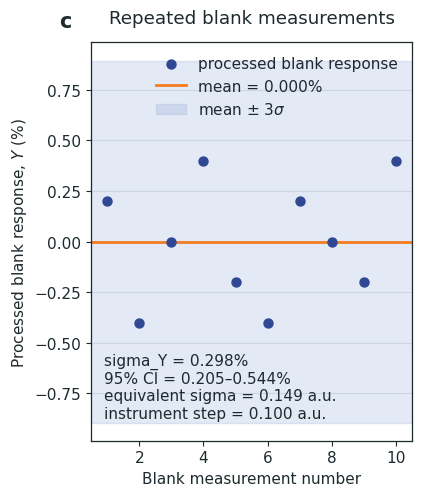

,I_before_au,I_after_au,processed_blank_response_percent
0,50.0,50.1000,0.2
1,50.1,49.8996,-0.4
2,49.9,49.9000,0.0
3,50.2,50.4008,0.4
4,49.8,49.7004,-0.2
5,50.1,49.8996,-0.4
6,50.0,50.1000,0.2
7,49.9,49.9000,0.0
8,50.2,50.0996,-0.2
9,49.8,49.9992,0.4


In [7]:
if BLANK_NOISE_MODE == "paired_processed_response":
    blank_response_percent = (
        100.0 * (BLANK_AFTER_AU - BLANK_BEFORE_AU) / BLANK_BEFORE_AU
    )
    blank_response_mean_percent = float(np.mean(blank_response_percent))
    blank_response_sigma_percent = float(np.std(blank_response_percent, ddof=1))
    paired_before_after_correlation = float(
        np.corrcoef(BLANK_BEFORE_AU, BLANK_AFTER_AU)[0, 1]
    )

    # Map the normalized blank response back into the absolute-signal units used
    # by this simple calibration demonstration.
    blank_measurements_au = BASELINE_SIGNAL_AU * (
        1.0 + blank_response_percent / 100.0
    )
    blank_mean = float(np.mean(blank_measurements_au))
    blank_sigma = BASELINE_SIGNAL_AU * blank_response_sigma_percent / 100.0
    blank_mode_label = "paired processed response"
else:
    blank_measurements_au = DIRECT_BLANK_SIGNALS_AU.copy()
    blank_mean = float(np.mean(blank_measurements_au))
    blank_sigma = float(np.std(blank_measurements_au, ddof=1))
    blank_response_percent = (
        100.0 * (blank_measurements_au - blank_mean) / blank_mean
    )
    blank_response_mean_percent = float(np.mean(blank_response_percent))
    blank_response_sigma_percent = float(np.std(blank_response_percent, ddof=1))
    paired_before_after_correlation = np.nan
    blank_mode_label = "direct signal"

blank_n = len(blank_response_percent)
blank_df = blank_n - 1
blank_sigma_ci_low_au = blank_sigma * np.sqrt(
    blank_df / chi2.ppf(0.975, blank_df)
)
blank_sigma_ci_high_au = blank_sigma * np.sqrt(
    blank_df / chi2.ppf(0.025, blank_df)
)
blank_sigma_ci_low_percent = 100 * blank_sigma_ci_low_au / BASELINE_SIGNAL_AU
blank_sigma_ci_high_percent = 100 * blank_sigma_ci_high_au / BASELINE_SIGNAL_AU

fig3, ax3 = journal_axes("Repeated blank measurements", "c")
blank_index = np.arange(1, len(blank_response_percent) + 1)
ax3.scatter(blank_index, blank_response_percent, color=ROYAL_BLUE, s=42, zorder=3,
            label="processed blank response")
ax3.axhline(blank_response_mean_percent, color=HABANERO_ORANGE, linewidth=2.0,
            label=f"mean = {blank_response_mean_percent:.3f}%")
ax3.axhspan(blank_response_mean_percent - LOD_FACTOR * blank_response_sigma_percent,
            blank_response_mean_percent + LOD_FACTOR * blank_response_sigma_percent,
            color=POWDER_BLUE, alpha=0.25,
            label=fr"mean $\pm$ {LOD_FACTOR:g}$\sigma$")
ax3.set_xlim(0.5, len(blank_response_percent) + 0.5)
ax3.set_xlabel("Blank measurement number")
ax3.set_ylabel(r"Processed blank response, $Y$ (%)")
ax3.legend(frameon=False, loc="best")
ax3.text(0.04, 0.05,
         f"sigma_Y = {blank_response_sigma_percent:.3f}%\n"
         f"95% CI = {blank_sigma_ci_low_percent:.3f}–{blank_sigma_ci_high_percent:.3f}%\n"
         f"equivalent sigma = {blank_sigma:.3f} a.u.\n"
         f"instrument step = {INSTRUMENT_SIGNAL_STEP_AU:.3f} a.u.",
         transform=ax3.transAxes, va="bottom", color=BLACK)
fig3.tight_layout()

if SAVE_FIGURES:
    fig3.savefig(FIGURE_DIRECTORY / "03_blank_noise.png", dpi=FIGURE_DPI,
                 bbox_inches="tight", facecolor="white")
    fig3.savefig(FIGURE_DIRECTORY / "03_blank_noise.svg",
                 bbox_inches="tight", facecolor="white")
plt.show()

if BLANK_NOISE_MODE == "paired_processed_response":
    blank_pair_table = pd.DataFrame({
        "I_before_au": BLANK_BEFORE_AU,
        "I_after_au": BLANK_AFTER_AU,
        "processed_blank_response_percent": blank_response_percent,
    })
else:
    blank_pair_table = pd.DataFrame({
        "direct_blank_signal_au": blank_measurements_au,
        "processed_blank_response_percent": blank_response_percent,
    })

blank_pair_table.round(4)

## 5. Simulated calibration and selected linear range

The receptor model generates the mean response. Each nonzero concentration uses its own SD from `CALIBRATION_NOISE_SD_AU`; therefore the blank can be clean while some sample levels are noisy. Only concentrations up to `LINEAR_RANGE_MAX_NM` are used for the linear fit.

When `USE_WEIGHTED_REGRESSION=True`, points with larger uncertainty in their mean receive less influence on the fitted line. This is useful when the variance changes with concentration.

In [8]:
rng = np.random.default_rng(RANDOM_SEED)
rows = []

for c, level_sigma in zip(CALIBRATION_CONCENTRATIONS_NM, CALIBRATION_NOISE_SD_AU):
    if c == 0:
        measured = blank_measurements_au.copy()
    else:
        measured = ideal_signal(c) + rng.normal(0, level_sigma, REPLICATES_PER_LEVEL)
    for replicate, value in enumerate(measured, start=1):
        rows.append({"concentration_nM": c, "replicate": replicate, "signal_au": value})

raw = pd.DataFrame(rows)
summary = (
    raw.groupby("concentration_nM", as_index=False)
       .agg(mean_signal_au=("signal_au", "mean"),
            sd_signal_au=("signal_au", "std"),
            n=("signal_au", "size"))
)

# Keep the smooth SD used to generate each simulated level separate from the
# SD estimated from a small random replicate sample. The zero-level reference
# is the processed blank SD calculated above.
expected_noise_by_level = {
    float(c): (
        blank_sigma if c == 0 else float(level_sigma)
    )
    for c, level_sigma in zip(
        CALIBRATION_CONCENTRATIONS_NM, CALIBRATION_NOISE_SD_AU
    )
}
summary["expected_noise_sd_au"] = summary["concentration_nM"].map(
    expected_noise_by_level
)

# Exact chi-square confidence interval for the underlying normal-population SD.
sd_interval_alpha = 1.0 - NOISE_SD_CONFIDENCE_LEVEL
summary["sd_degrees_freedom"] = summary["n"] - 1
summary["sd_ci_low_au"] = summary["sd_signal_au"] * np.sqrt(
    summary["sd_degrees_freedom"]
    / chi2.ppf(1.0 - sd_interval_alpha / 2.0,
               summary["sd_degrees_freedom"])
)
summary["sd_ci_high_au"] = summary["sd_signal_au"] * np.sqrt(
    summary["sd_degrees_freedom"]
    / chi2.ppf(sd_interval_alpha / 2.0,
               summary["sd_degrees_freedom"])
)
summary["approx_relative_uncertainty_of_sd"] = 1.0 / np.sqrt(
    2.0 * summary["sd_degrees_freedom"]
)

# Fit the two-component heteroscedastic noise model directly. The proportional
# term is expressed as a dimensionless CV of the net response, not of C itself:
# sigma_y = sqrt(sigma_0^2 + (r * |mean_y - blank_mean|)^2).
noise_fit = summary.dropna(subset=["sd_signal_au"]).copy()
noise_fit["net_response_au"] = np.abs(
    noise_fit["mean_signal_au"] - blank_mean
)
noise_fit = noise_fit[noise_fit["sd_signal_au"] > 0].copy()

def noise_model_from_net_response(net_response_au, sigma0_au, proportional_cv):
    net_response_au = np.asarray(net_response_au, dtype=float)
    return np.sqrt(sigma0_au**2 + (proportional_cv * net_response_au)**2)

positive_net = noise_fit["net_response_au"].to_numpy() > 0
initial_r_candidates = (
    noise_fit.loc[positive_net, "sd_signal_au"].to_numpy()
    / noise_fit.loc[positive_net, "net_response_au"].to_numpy()
)
initial_r = float(np.median(initial_r_candidates)) if len(initial_r_candidates) else 0.05
initial_r = max(initial_r, 1e-4)

def noise_fit_residuals(log_parameters):
    sigma0_au, proportional_cv = np.exp(log_parameters)
    predicted = noise_model_from_net_response(
        noise_fit["net_response_au"].to_numpy(), sigma0_au, proportional_cv
    )
    observed = noise_fit["sd_signal_au"].to_numpy()
    # Approximate precision weighting for an SD estimated from n replicates.
    sd_information_weight = np.sqrt(2 * np.maximum(noise_fit["n"].to_numpy() - 1, 1))
    return sd_information_weight * (np.log(predicted) - np.log(observed))

noise_fit_result = least_squares(
    noise_fit_residuals,
    np.log([max(blank_sigma, 1e-8), initial_r]),
)
fitted_additive_sigma_au, fitted_proportional_cv = np.exp(noise_fit_result.x)

summary["net_response_au"] = np.abs(summary["mean_signal_au"] - blank_mean)
summary["fitted_noise_sd_au"] = noise_model_from_net_response(
    summary["net_response_au"], fitted_additive_sigma_au, fitted_proportional_cv
)
summary["mean_weight_n_over_sigma2"] = (
    summary["n"] / summary["fitted_noise_sd_au"]**2
)

linear = summary[summary["concentration_nM"] <= LINEAR_RANGE_MAX_NM].copy()
if len(linear) < 3:
    raise ValueError("The selected linear range must contain at least three levels including zero.")

x = linear["concentration_nM"].to_numpy()
y = linear["mean_signal_au"].to_numpy()
sigma_of_mean = (
    linear["fitted_noise_sd_au"].to_numpy()
    / np.sqrt(linear["n"].to_numpy())
)

if USE_WEIGHTED_REGRESSION:
    slope, intercept = np.polyfit(x, y, 1, w=1.0 / sigma_of_mean)
    fit_type = "weighted linear regression"
else:
    slope, intercept = np.polyfit(x, y, 1)
    fit_type = "ordinary linear regression"

fitted = slope * x + intercept
residuals = y - fitted
ss_res = np.sum(residuals**2)
ss_tot = np.sum((y - np.mean(y))**2)
r_squared = 1.0 - ss_res / ss_tot

response_span = max(float(fitted.max() - fitted.min()), np.finfo(float).eps)
max_residual_percent = 100.0 * float(np.max(np.abs(residuals))) / response_span
linearity_passes_teaching_rules = bool(
    (r_squared >= MIN_R_SQUARED)
    and (max_residual_percent <= MAX_RESIDUAL_PERCENT_OF_RESPONSE_SPAN)
)

summary.round(4)

,concentration_nM,mean_signal_au,sd_signal_au,n,expected_noise_sd_au,sd_degrees_freedom,sd_ci_low_au,sd_ci_high_au,approx_relative_uncertainty_of_sd,net_response_au,fitted_noise_sd_au,mean_weight_n_over_sigma2
0,0.00,50.0000,0.1491,10,0.1491,9,0.1025,0.2721,0.2357,0.0000,0.1454,472.7199
1,0.10,50.0822,0.1803,5,0.1500,4,0.1080,0.5181,0.3536,0.0822,0.1455,236.2736
2,0.25,50.3155,0.0640,5,0.1510,4,0.0384,0.1839,0.3536,0.3155,0.1458,235.0937
3,0.50,50.7180,0.2821,5,0.1520,4,0.1690,0.8108,0.3536,0.7180,0.1475,229.9462
4,1.00,51.5389,0.1109,5,0.1590,4,0.0664,0.3185,0.3536,1.5389,0.1545,209.5177
5,2.00,52.9769,0.1691,5,0.1820,4,0.1013,0.4859,0.3536,2.9769,0.1769,159.7662
6,4.00,55.5311,0.4709,5,0.2520,4,0.2821,1.3532,0.3536,5.5311,0.2370,89.0243
7,6.00,58.5211,0.3847,5,0.3330,4,0.2305,1.1056,0.3536,8.5211,0.3229,47.9627
8,8.00,61.0434,0.2580,5,0.4170,4,0.1546,0.7414,0.3536,11.0434,0.4009,31.1100
9,10.00,63.4935,0.6139,5,0.5000,4,0.3678,1.7642,0.3536,13.4935,0.4791,21.7847


## 6. Sensitivity, resolution, LOD and LOQ

The fitted signal-domain noise model is:

$$
\sigma_Y(C)=\sqrt{\sigma_0^2+\left[r\,\mu_{net}(C)\right]^2}
$$

where $\sigma_0$ is constant **in the processed net-response variable** and $r$ is the proportional CV of the net response. The fitted $\sigma_0$ is not automatically the physical electronic floor: baseline-proportional drift, normalization or extraction error, surface variability and other effects can become constant after subtraction or normalization and therefore land inside $\sigma_0$. It is fitted nonlinearly to replicate SDs; one straight log–log line cannot recover both terms because the log–log slope changes from zero to one.

The conventional blank-only teaching estimates are retained but labelled explicitly:

$$
C_{3\sigma}=\frac{3\sigma_{blank}}{|S|},\qquad
C_{10\sigma}=\frac{10\sigma_{blank}}{|S|}
$$

These are conventional threshold estimates, not a full detection-probability calculation.

For false-positive probability $\alpha$ and false-negative probability $\beta$, a useful **known-parameter teaching approximation** solves:

$$
|S|C_D=z_{1-\alpha}\sigma_0+z_{1-\beta}\sigma_Y(C_D)
$$

This equation treats the blank mean, variances and calibration slope as known. With a finite blank series, even the critical level for one future measurement should include uncertainty in the estimated blank mean and SD:

$$
Y_{critical}=\bar Y_{blank}
+t_{1-\alpha,n-1}s_{blank}\sqrt{1+\frac{1}{n}}
$$

Slope and intercept uncertainty require a calibration prediction-interval method, such as an appropriate Hubaux–Vos implementation; the simple $t$ correction alone is still not a complete method-validation LOD.

The precision-only LOQ is the lowest concentration satisfying:

$$
\frac{\sigma_C(C)}{C}
=\frac{\sigma_Y(C)}{|S|C}
\leq p_{max}
$$

A real LOQ must also pass accuracy or recovery criteria. Resolution remains distinct: it describes the concentration separation required under a chosen noise rule.

In [17]:
instrument_resolution_nM = INSTRUMENT_SIGNAL_STEP_AU / abs(slope)

low_level = summary[
    (summary["concentration_nM"] > 0)
    & (summary["concentration_nM"] <= LOW_LEVEL_PRECISION_MAX_NM)
].copy()
if low_level.empty:
    raise ValueError("No nonzero calibration points fall inside LOW_LEVEL_PRECISION_MAX_NM.")

pooled_degrees_freedom = np.sum(low_level["n"] - 1)
pooled_low_level_sigma = float(np.sqrt(
    np.sum((low_level["n"] - 1) * low_level["sd_signal_au"]**2)
    / pooled_degrees_freedom
))
sample_vs_blank_sigma = float(np.sqrt(blank_sigma**2 + pooled_low_level_sigma**2))

blank_noise_resolution_nM = RESOLUTION_NOISE_FACTOR * blank_sigma / abs(slope)
sample_aware_resolution_nM = RESOLUTION_NOISE_FACTOR * sample_vs_blank_sigma / abs(slope)
practical_resolution_nM = max(instrument_resolution_nM, sample_aware_resolution_nM)

conventional_blank_threshold_nM = LOD_FACTOR * blank_sigma / abs(slope)
conventional_ten_sigma_nM = LOQ_FACTOR * blank_sigma / abs(slope)
sample_aware_heuristic_lod_nM = LOD_FACTOR * sample_vs_blank_sigma / abs(slope)

def fitted_noise_at_concentration(concentration_nM):
    net_response = abs(slope) * np.asarray(concentration_nM, dtype=float)
    return noise_model_from_net_response(
        net_response, fitted_additive_sigma_au, fitted_proportional_cv
    )

z_false_positive = float(norm.ppf(1.0 - FALSE_POSITIVE_RATE))
z_false_negative = float(norm.ppf(1.0 - FALSE_NEGATIVE_RATE))
critical_signal_au = z_false_positive * fitted_additive_sigma_au
critical_concentration_nM = critical_signal_au / abs(slope)

# A one-sided prediction threshold for one future blank-like observation
# compared with the estimated mean of n blanks. This accounts for finite-n
# blank mean and SD uncertainty, but not calibration slope/intercept uncertainty.
finite_blank_prediction_factor = float(
    t.ppf(1.0 - FALSE_POSITIVE_RATE, blank_df)
    * np.sqrt(1.0 + 1.0 / blank_n)
)
finite_blank_critical_signal_au = finite_blank_prediction_factor * blank_sigma
finite_blank_critical_concentration_nM = (
    finite_blank_critical_signal_au / abs(slope)
)

def detection_equation(concentration_nM):
    return (
        abs(slope) * concentration_nM
        - z_false_positive * fitted_additive_sigma_au
        - z_false_negative * float(fitted_noise_at_concentration(concentration_nM))
    )

if z_false_negative * fitted_proportional_cv >= 1.0:
    formal_detection_limit_nM = np.nan
    formal_detection_status = "no finite solution under the fitted model"
else:
    upper = max(LINEAR_RANGE_MAX_NM, conventional_blank_threshold_nM, 1e-9)
    while detection_equation(upper) <= 0 and upper < 1e12:
        upper *= 2.0
    formal_detection_limit_nM = float(brentq(detection_equation, 0.0, upper))
    formal_detection_status = "finite solution"

if fitted_proportional_cv >= LOQ_MAX_RELATIVE_SD:
    precision_only_loq_nM = np.nan
    precision_loq_status = "no finite solution: proportional CV exceeds precision target"
else:
    precision_only_loq_nM = (
        fitted_additive_sigma_au
        / (abs(slope) * np.sqrt(
            LOQ_MAX_RELATIVE_SD**2 - fitted_proportional_cv**2
        ))
    )
    precision_loq_status = "precision criterion reached; accuracy still requires validation"

formal_lod_inside_linear_range = bool(
    np.isfinite(formal_detection_limit_nM)
    and formal_detection_limit_nM <= LINEAR_RANGE_MAX_NM
)
precision_loq_inside_linear_range = bool(
    np.isfinite(precision_only_loq_nM)
    and precision_only_loq_nM <= LINEAR_RANGE_MAX_NM
)

results = pd.Series({
    "sensitivity / slope (a.u. per nM)": slope,
    "intercept (a.u.)": intercept,
    "selected linear range": f"0 to {LINEAR_RANGE_MAX_NM:g} nM",
    "regression": fit_type,
    "R squared": r_squared,
    "maximum residual (% of response span)": max_residual_percent,
    "passes both teaching linearity checks": linearity_passes_teaching_rules,
    "blank noise mode": blank_mode_label,
    "blank population": BLANK_POPULATION_DESCRIPTION,
    "processed blank response sigma (%)": blank_response_sigma_percent,
    "blank sigma 95% CI low (%)": blank_sigma_ci_low_percent,
    "blank sigma 95% CI high (%)": blank_sigma_ci_high_percent,
    "paired before/after correlation": paired_before_after_correlation,
    "blank mean (a.u.)": blank_mean,
    "blank sigma (a.u.)": blank_sigma,
    "fitted additive floor sigma_0 (a.u.)": fitted_additive_sigma_au,
    "fitted proportional response CV r": fitted_proportional_cv,
    "fitted concentration-equivalent floor sigma_0/|S| (nM)": fitted_additive_sigma_au / abs(slope),
    "empirical blank concentration-equivalent SD (nM)": blank_sigma / abs(slope),
    f"pooled sample sigma from >0 to {LOW_LEVEL_PRECISION_MAX_NM:g} nM (a.u.)": pooled_low_level_sigma,
    "combined blank/sample separation sigma (a.u.)": sample_vs_blank_sigma,
    "instrument signal step (a.u.)": INSTRUMENT_SIGNAL_STEP_AU,
    "instrument-limited resolution (nM)": instrument_resolution_nM,
    f"blank-noise resolution ({RESOLUTION_NOISE_FACTOR:g} sigma) (nM)": blank_noise_resolution_nM,
    f"sample-aware resolution ({RESOLUTION_NOISE_FACTOR:g} sigma) (nM)": sample_aware_resolution_nM,
    "practical resolution: larger of instrument and sample-aware (nM)": practical_resolution_nM,
    f"conventional blank threshold ({LOD_FACTOR:g} sigma / slope) (nM)": conventional_blank_threshold_nM,
    f"conventional {LOQ_FACTOR:g} sigma concentration (nM)": conventional_ten_sigma_nM,
    "sample-aware heuristic LOD (nM)": sample_aware_heuristic_lod_nM,
    f"known-parameter z critical concentration at alpha={FALSE_POSITIVE_RATE:g} (nM)": critical_concentration_nM,
    "finite-blank one-sided prediction factor": finite_blank_prediction_factor,
    f"finite-blank critical concentration at alpha={FALSE_POSITIVE_RATE:g} (nM)": finite_blank_critical_concentration_nM,
    f"known-parameter detection approximation alpha={FALSE_POSITIVE_RATE:g}, beta={FALSE_NEGATIVE_RATE:g} (nM)": formal_detection_limit_nM,
    "known-parameter detection status": formal_detection_status,
    "known-parameter detection approximation inside selected linear range": formal_lod_inside_linear_range,
    f"precision-only LOQ at relative SD <= {LOQ_MAX_RELATIVE_SD:.0%} (nM)": precision_only_loq_nM,
    "precision-only LOQ status": precision_loq_status,
    "precision-only LOQ inside selected linear range": precision_loq_inside_linear_range,
})
results

sensitivity / slope (a.u. per nM)                                                                                1.387351
intercept (a.u.)                                                                                                50.026976
selected linear range                                                                                          0 to 10 nM
regression                                                                                     weighted linear regression
R squared                                                                                                        0.998834
maximum residual (% of response span)                                                                            2.933757
passes both teaching linearity checks                                                                                True
blank noise mode                                                                                paired processed response
blank population        

## 7. Separate Figure 4 — calibration, LOD and LOQ

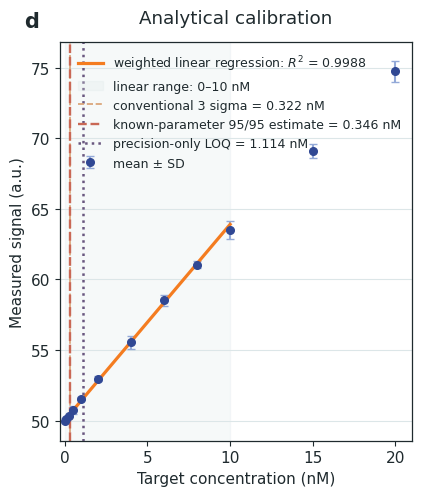

In [10]:
fig4, ax4 = journal_axes("Analytical calibration", "d")

ax4.errorbar(
    summary["concentration_nM"], summary["mean_signal_au"],
    yerr=summary["sd_signal_au"].fillna(0),
    fmt="o", markersize=5.5, color=ROYAL_BLUE, ecolor=POWDER_BLUE,
    capsize=3, label="mean ± SD",
)

fit_x = np.linspace(0, LINEAR_RANGE_MAX_NM, 200)
ax4.plot(fit_x, slope * fit_x + intercept, color=HABANERO_ORANGE,
         linewidth=2.3, label=fr"{fit_type}: $R^2$ = {r_squared:.4f}")
ax4.axvspan(0, LINEAR_RANGE_MAX_NM, color=LIGHT_GREY, alpha=0.24,
            label=f"linear range: 0–{LINEAR_RANGE_MAX_NM:g} nM")
ax4.axvline(conventional_blank_threshold_nM, color=WARM_SAND,
            linestyle="--", linewidth=1.2,
            label=f"conventional {LOD_FACTOR:g} sigma = {conventional_blank_threshold_nM:.3f} nM")
if np.isfinite(formal_detection_limit_nM):
    ax4.axvline(formal_detection_limit_nM, color=MUTED_CORAL,
                linestyle="--", linewidth=1.7,
                label=f"known-parameter 95/95 estimate = {formal_detection_limit_nM:.3f} nM")
if np.isfinite(precision_only_loq_nM):
    ax4.axvline(precision_only_loq_nM, color=MUTED_PLUM,
                linestyle=":", linewidth=1.8,
                label=f"precision-only LOQ = {precision_only_loq_nM:.3f} nM")
ax4.set_xlim(left=-0.3)
ax4.set_xlabel("Target concentration (nM)")
ax4.set_ylabel("Measured signal (a.u.)")
ax4.legend(frameon=False, loc="best", fontsize=9)
fig4.tight_layout()

if SAVE_FIGURES:
    fig4.savefig(FIGURE_DIRECTORY / "04_calibration_lod_loq.png", dpi=FIGURE_DPI,
                 bbox_inches="tight", facecolor="white")
    fig4.savefig(FIGURE_DIRECTORY / "04_calibration_lod_loq.svg",
                 bbox_inches="tight", facecolor="white")
plt.show()

## 8. Separate Figure 5 — every calibration point can have different noise

The vertical spread is not required to be constant. This is called **heteroscedasticity**. However, an SD calculated from only a few replicates is itself uncertain and can jump up and down even when the underlying SD changes smoothly.

For normally distributed replicates:

$$
\frac{(n-1)s^2}{\sigma^2}\sim\chi^2_{n-1}
$$

The figure therefore separates the smooth SD used to generate the simulation from the observed replicate SD. Whiskers are exact chi-square confidence intervals for the underlying SD. With five nonzero replicates, the broad intervals are expected rather than evidence by themselves that the experiment failed.

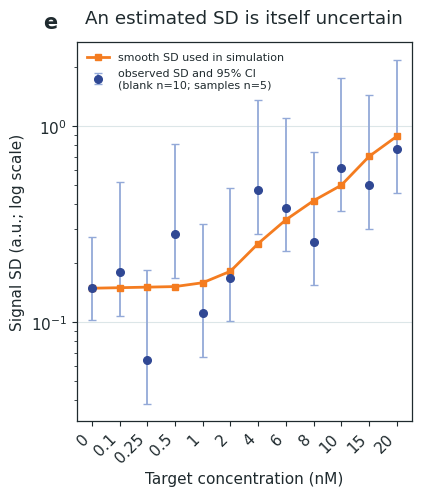

In [11]:
fig5, ax5 = journal_axes("An estimated SD is itself uncertain", "e")
noise_positions = np.arange(len(summary))
observed_sd = summary["sd_signal_au"].to_numpy()
sd_ci_low = summary["sd_ci_low_au"].to_numpy()
sd_ci_high = summary["sd_ci_high_au"].to_numpy()
sd_asymmetric_error = np.vstack([
    observed_sd - sd_ci_low,
    sd_ci_high - observed_sd,
])

ax5.errorbar(
    noise_positions,
    observed_sd,
    yerr=sd_asymmetric_error,
    fmt="o",
    markersize=5.5,
    color=ROYAL_BLUE,
    ecolor=POWDER_BLUE,
    elinewidth=1.3,
    capsize=3,
    label=(
        fr"observed SD and {NOISE_SD_CONFIDENCE_LEVEL:.0%} CI"
        f"\n(blank n={blank_n}; samples n={REPLICATES_PER_LEVEL})"
    ),
)
ax5.plot(
    noise_positions,
    summary["expected_noise_sd_au"],
    color=HABANERO_ORANGE,
    linewidth=2.0,
    marker="s",
    markersize=4.0,
    label="smooth SD used in simulation",
)
ax5.set_xticks(noise_positions)
ax5.set_xticklabels([f"{c:g}" for c in summary["concentration_nM"]],
                    rotation=45, ha="right")
ax5.set_yscale("log")
ax5.set_xlabel("Target concentration (nM)")
ax5.set_ylabel("Signal SD (a.u.; log scale)")
ax5.legend(frameon=False, loc="upper left", fontsize=8)
fig5.tight_layout()

if SAVE_FIGURES:
    fig5.savefig(FIGURE_DIRECTORY / "05_noise_by_concentration.png", dpi=FIGURE_DPI,
                 bbox_inches="tight", facecolor="white")
    fig5.savefig(FIGURE_DIRECTORY / "05_noise_by_concentration.svg",
                 bbox_inches="tight", facecolor="white")
plt.show()

## 9. Separate Figure 6 — additive proportional and total noise

Every observed calibration SD is shown together with the fitted components:

$$
\sigma_Y(C)=\sqrt{\sigma_0^2+\left[r\mu_{net}(C)\right]^2}
$$

Here, *additive* means constant in the final net-response variable; it does not identify a physical mechanism. A fluctuation proportional to the large baseline $I_U$ can become nearly constant after subtraction or normalization and therefore be absorbed into $\sigma_0$. Do not compare fitted $\sigma_0$ directly with the Figure 7 electronic bars unless both have been propagated into the same observable, bandwidth, timescale and replicate population.

This response-domain floor controls the low-response plateau. The proportional component dominates only when the net response becomes sufficiently large.

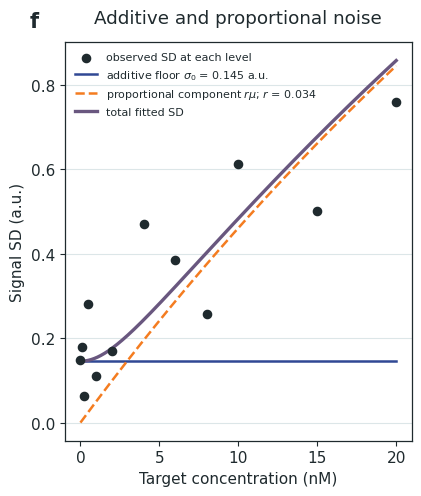

In [12]:
fig6, ax6 = journal_axes("Additive and proportional noise", "f")
noise_curve_concentration = np.linspace(
    0, float(np.max(CALIBRATION_CONCENTRATIONS_NM)), 500
)
noise_curve_net_response = np.abs(
    ideal_signal(noise_curve_concentration) - BASELINE_SIGNAL_AU
)
noise_curve_additive = np.full_like(
    noise_curve_concentration, fitted_additive_sigma_au
)
noise_curve_proportional = fitted_proportional_cv * noise_curve_net_response
noise_curve_total = noise_model_from_net_response(
    noise_curve_net_response, fitted_additive_sigma_au, fitted_proportional_cv
)

ax6.scatter(summary["concentration_nM"], summary["sd_signal_au"],
            color=BLACK, s=35, zorder=4, label="observed SD at each level")
ax6.plot(noise_curve_concentration, noise_curve_additive,
         color=ROYAL_BLUE, linewidth=1.8,
         label=fr"additive floor $\sigma_0$ = {fitted_additive_sigma_au:.3f} a.u.")
ax6.plot(noise_curve_concentration, noise_curve_proportional,
         color=HABANERO_ORANGE, linewidth=1.8, linestyle="--",
         label=fr"proportional component $r\mu$; $r$ = {fitted_proportional_cv:.3f}")
ax6.plot(noise_curve_concentration, noise_curve_total,
         color=MUTED_PLUM, linewidth=2.4,
         label="total fitted SD")
ax6.set_xlabel("Target concentration (nM)")
ax6.set_ylabel("Signal SD (a.u.)")
ax6.legend(frameon=False, loc="best", fontsize=8)
fig6.tight_layout()

if SAVE_FIGURES:
    fig6.savefig(FIGURE_DIRECTORY / "06_additive_proportional_noise_model.png",
                 dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
    fig6.savefig(FIGURE_DIRECTORY / "06_additive_proportional_noise_model.svg",
                 bbox_inches="tight", facecolor="white")
plt.show()

## 10. Separate Figure 7 — physical electronic-noise components

This is a **design-diagnostic example**, not an additional term to add to the measured blank SD. Each contribution is converted into the same input-referred rms current unit:

$$
i_{J,rms}=\sqrt{\frac{4k_BT B}{R_f}},\qquad
i_{shot,rms}=\sqrt{2qIB}
$$

$$
i_{op,spot}=\sqrt{\left(i_n\sqrt{B}\right)^2+
\left(2\pi f_{char}C_{dl}e_n\sqrt{B}\right)^2},\qquad
i_{ADC,rms}=\frac{I_{span}/2^{N_{eff}}}{\sqrt{12}}
$$

The plotted op-amp bar uses the **narrow-band spot approximation**: a band of width $B$ centred near $f_{char}$. It is not the integral from DC to $B$. For flat $e_n$ and a purely capacitive coupling integrated from zero to an upper frequency $f_{BW}$:

$$
i_{cap,0\rightarrow f_{BW}}
=2\pi C_{dl}e_n
\sqrt{\frac{f_{BW}^3}{3}}
$$

The notebook reports both capacitive calculations so their different frequency-band assumptions cannot be confused. A real potentiostat calculation should integrate the frequency-dependent op-amp spectrum, electrode impedance, noise gain and filter transfer function. The ADC expression assumes quantization error samples many codes. Edit the electronic-noise inputs in Section 0 to see how the values change.

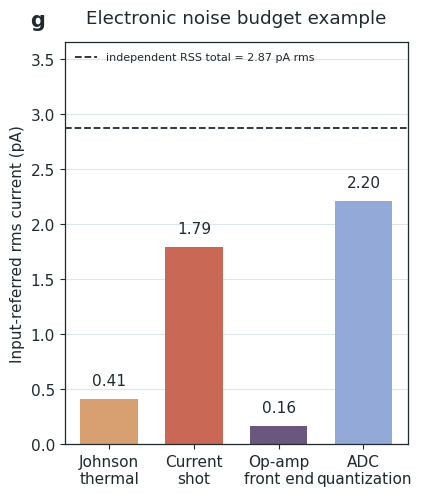

,calculation,input_referred_rms_current_pA,frequency interpretation
0,Johnson thermal,0.4058,white over ENBW B
1,current shot,1.7901,white over ENBW B
2,op-amp input-current term,0.0063,white over ENBW B
3,capacitive voltage-noise: spot band at f_char,0.1590,narrow band of width B near f_char; used in bar
4,capacitive voltage-noise: integrated 0 to f_BW,0.0092,broad band from 0 to separate upper frequency ...
5,plotted op-amp RSS using spot model,0.1591,current term plus narrow-band spot capacitive ...
6,ADC quantization,2.2024,ideal uniform quantization model


In [13]:
BOLTZMANN_J_PER_K = 1.380649e-23
ELEMENTARY_CHARGE_C = 1.602176634e-19

johnson_current_rms_a = np.sqrt(
    4.0 * BOLTZMANN_J_PER_K * TEMPERATURE_K
    * EFFECTIVE_NOISE_BANDWIDTH_HZ / FEEDBACK_RESISTANCE_OHM
)
shot_current_rms_a = np.sqrt(
    2.0 * ELEMENTARY_CHARGE_C * MEAN_FARADAIC_CURRENT_A
    * EFFECTIVE_NOISE_BANDWIDTH_HZ
)

opamp_current_noise_rms_a = (
    OPAMP_CURRENT_NOISE_DENSITY_A_PER_SQRT_HZ
    * np.sqrt(EFFECTIVE_NOISE_BANDWIDTH_HZ)
)
opamp_voltage_coupled_density_a_per_sqrt_hz = (
    2.0 * np.pi * CHARACTERISTIC_FREQUENCY_HZ
    * DOUBLE_LAYER_CAPACITANCE_F
    * OPAMP_VOLTAGE_NOISE_DENSITY_V_PER_SQRT_HZ
)
opamp_voltage_coupled_rms_a = (
    opamp_voltage_coupled_density_a_per_sqrt_hz
    * np.sqrt(EFFECTIVE_NOISE_BANDWIDTH_HZ)
)
# Alternative broadband integral from 0 to CAPACITIVE_INTEGRATION_UPPER_HZ,
# assuming flat voltage-noise density and purely capacitive coupling.
opamp_voltage_integrated_zero_to_bandwidth_rms_a = (
    2.0 * np.pi
    * DOUBLE_LAYER_CAPACITANCE_F
    * OPAMP_VOLTAGE_NOISE_DENSITY_V_PER_SQRT_HZ
    * np.sqrt(CAPACITIVE_INTEGRATION_UPPER_HZ**3 / 3.0)
)
opamp_total_rms_a = np.sqrt(
    opamp_current_noise_rms_a**2 + opamp_voltage_coupled_rms_a**2
)

adc_lsb_current_a = ADC_FULL_SCALE_CURRENT_SPAN_A / (2.0**ADC_EFFECTIVE_BITS)
adc_quantization_rms_a = adc_lsb_current_a / np.sqrt(12.0)

electronic_component_names = [
    "Johnson\nthermal",
    "Current\nshot",
    "Op-amp\nfront end",
    "ADC\nquantization",
]
electronic_component_rms_a = np.array([
    johnson_current_rms_a,
    shot_current_rms_a,
    opamp_total_rms_a,
    adc_quantization_rms_a,
])
electronic_component_rms_pa = 1e12 * electronic_component_rms_a
electronic_total_rss_pa = 1e12 * np.sqrt(
    np.sum(electronic_component_rms_a**2)
)

electronic_noise_budget = pd.DataFrame({
    "component": [name.replace("\n", " ") for name in electronic_component_names],
    "input_referred_rms_current_pA": electronic_component_rms_pa,
})

electronic_noise_diagnostics = pd.DataFrame({
    "calculation": [
        "Johnson thermal",
        "current shot",
        "op-amp input-current term",
        "capacitive voltage-noise: spot band at f_char",
        "capacitive voltage-noise: integrated 0 to f_BW",
        "plotted op-amp RSS using spot model",
        "ADC quantization",
    ],
    "input_referred_rms_current_pA": 1e12 * np.array([
        johnson_current_rms_a,
        shot_current_rms_a,
        opamp_current_noise_rms_a,
        opamp_voltage_coupled_rms_a,
        opamp_voltage_integrated_zero_to_bandwidth_rms_a,
        opamp_total_rms_a,
        adc_quantization_rms_a,
    ]),
    "frequency interpretation": [
        "white over ENBW B",
        "white over ENBW B",
        "white over ENBW B",
        "narrow band of width B near f_char; used in bar",
        "broad band from 0 to separate upper frequency f_BW; diagnostic only",
        "current term plus narrow-band spot capacitive term",
        "ideal uniform quantization model",
    ],
})

fig7, ax7 = journal_axes("Electronic noise budget example", "g")
component_colors = [WARM_SAND, MUTED_CORAL, MUTED_PLUM, POWDER_BLUE]
component_positions = np.arange(len(electronic_component_names))
bars = ax7.bar(
    component_positions,
    electronic_component_rms_pa,
    color=component_colors,
    width=0.68,
)
ax7.axhline(
    electronic_total_rss_pa,
    color=BLACK,
    linestyle="--",
    linewidth=1.3,
    label=fr"independent RSS total = {electronic_total_rss_pa:.2f} pA rms",
)
for bar, value in zip(bars, electronic_component_rms_pa):
    ax7.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.035 * electronic_total_rss_pa,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        color=BLACK,
    )
ax7.set_xticks(component_positions)
ax7.set_xticklabels(electronic_component_names)
ax7.set_ylabel("Input-referred rms current (pA)")
ax7.set_ylim(0, electronic_total_rss_pa * 1.27)
ax7.legend(frameon=False, loc="upper left", fontsize=8)
fig7.tight_layout()

if SAVE_FIGURES:
    fig7.savefig(FIGURE_DIRECTORY / "07_electronic_noise_budget.png",
                 dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
    fig7.savefig(FIGURE_DIRECTORY / "07_electronic_noise_budget.svg",
                 bbox_inches="tight", facecolor="white")
plt.show()

electronic_noise_diagnostics.round(4)

### What the four bars mean

- **Johnson thermal:** random thermal motion in the feedback resistance; controlled mainly by temperature, resistance and bandwidth.
- **Current shot:** discrete electron-transfer events; controlled mainly by average faradaic current and bandwidth.
- **Op-amp front end:** the example amplifier current-noise term plus the **narrow-band spot** voltage-noise approximation converted through $C_{dl}$. The diagnostic table also gives the distinct zero-to-$f_{BW}$ integrated value. Both are affected strongly by the stated band, capacitance and component choice.
- **ADC quantization:** the ideal digital step expressed as an rms term; controlled by current range and effective bit depth.

The dashed line is the root-sum-square total only under the simplifying assumption that the four terms are independent. Do not add this total to an empirical processed blank SD that already contains these electronic effects.

## 11. Separate Figure 8 — linearity requires residual inspection

$R^2$ is reported, but it does not define the linear range by itself. A reasonable range should also show residuals without systematic curvature and acceptable precision. The notebook applies the two editable teaching checks `MIN_R_SQUARED` and `MAX_RESIDUAL_PERCENT_OF_RESPONSE_SPAN`.

Change `LINEAR_RANGE_MAX_NM`, run the notebook again, and inspect this residual figure. Extending the range too far across the receptor saturation curve produces a systematic residual pattern even when $R^2$ still looks high.

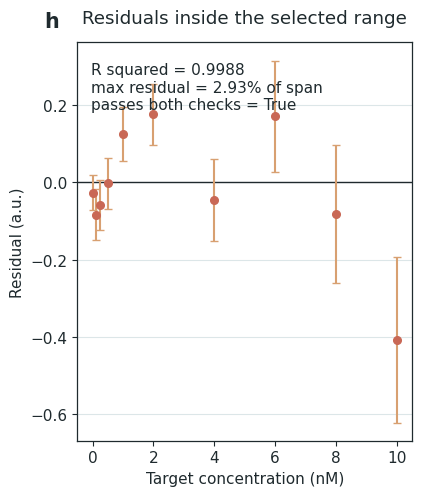

In [14]:
fig8, ax8 = journal_axes("Residuals inside the selected range", "h")
ax8.axhline(0, color=BLACK, linewidth=1.0)
ax8.errorbar(x, residuals, yerr=sigma_of_mean,
             fmt="o", markersize=5.5, color=MUTED_CORAL,
             ecolor=WARM_SAND, capsize=3)
ax8.set_xlabel("Target concentration (nM)")
ax8.set_ylabel("Residual (a.u.)")
ax8.text(0.04, 0.95,
         f"R squared = {r_squared:.4f}\n"
         f"max residual = {max_residual_percent:.2f}% of span\n"
         f"passes both checks = {linearity_passes_teaching_rules}",
         transform=ax8.transAxes, ha="left", va="top", color=BLACK)
fig8.tight_layout()

if SAVE_FIGURES:
    fig8.savefig(FIGURE_DIRECTORY / "08_linearity_residuals.png", dpi=FIGURE_DPI,
                 bbox_inches="tight", facecolor="white")
    fig8.savefig(FIGURE_DIRECTORY / "08_linearity_residuals.svg",
                 bbox_inches="tight", facecolor="white")
plt.show()

## 12. Separate Figure 9 — bandwidth averaging and drift

Narrowing effective bandwidth reduces approximately white noise:

$$
\sigma_{white}(T)
=\sigma_{ref}\sqrt{\frac{T_{ref}}{T}},
\qquad B\approx\frac{1}{2T}
$$

so $\sigma_{white}\sqrt{T}$ is constant in this ideal model. Averaging improves one result, but it costs time; it does not create unlimited information per unit time.

The demonstration treats linear drift as a deterministic midpoint-referenced bias:

$$
b_{drift}(T)=\frac{dT}{2}
$$

and combines random SD and bias as a root-mean-square teaching error:

$$
\varepsilon_{noise}(T)
=\sqrt{\sigma_{white}(T)^2+b_{drift}(T)^2}
$$

To show why the narrowest filter is not automatically best, the example maps the equivalent noise bandwidth onto a first-order low-pass. For that filter,

$$
B_{ENBW}=\frac{\pi}{2}f_c,
\qquad f_c=\frac{2B_{ENBW}}{\pi}
$$

and a sinusoidal component at $f_{signal}$ retains the fraction:

$$
g(T)=\frac{1}{\sqrt{1+[f_{signal}/f_c(T)]^2}}
$$

and plots $\varepsilon_{usable}=\varepsilon_{noise}/g$. This is not a universal matched-filter or Allan-variance calculation. Replace it with the real signal waveform, filter transfer function, power spectrum and drift model for an actual instrument.

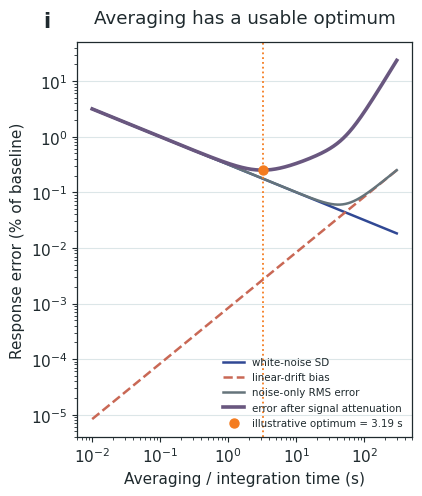

white-noise SD at reference time (%)           1.0000
reference averaging time (s)                   0.1000
linear drift rate (% per min)                  0.1000
signal characteristic frequency (Hz)           0.1000
noise-only optimum time (s)                   41.6017
usable illustrative optimum time (s)           3.1943
effective bandwidth at usable optimum (Hz)     0.1565
one-pole cutoff at usable optimum (Hz)         0.0997
signal retained at usable optimum (%)         70.5869
usable error at optimum (% baseline)           0.2507
dtype: float64

In [15]:
averaging_time_s = np.logspace(
    np.log10(AVERAGING_TIME_MIN_S),
    np.log10(AVERAGING_TIME_MAX_S),
    700,
)
effective_bandwidth_hz = 1.0 / (2.0 * averaging_time_s)
equivalent_cutoff_hz = 2.0 * effective_bandwidth_hz / np.pi

white_sd_percent = WHITE_SD_AT_REFERENCE_TIME_PERCENT * np.sqrt(
    AVERAGING_REFERENCE_TIME_S / averaging_time_s
)
drift_rate_percent_per_s = LINEAR_DRIFT_RATE_PERCENT_PER_MIN / 60.0
drift_midpoint_bias_percent = (
    0.5 * drift_rate_percent_per_s * averaging_time_s
)
noise_only_rmse_percent = np.sqrt(
    white_sd_percent**2 + drift_midpoint_bias_percent**2
)

# Illustrative first-order low-pass response at one characteristic signal
# frequency. Real SWV processing requires its actual transfer function.
signal_retained_fraction = 1.0 / np.sqrt(
    1.0
    + (SIGNAL_CHARACTERISTIC_FREQUENCY_HZ / equivalent_cutoff_hz)**2
)
usable_error_percent = noise_only_rmse_percent / signal_retained_fraction

if drift_rate_percent_per_s > 0:
    noise_only_optimum_time_s = (
        WHITE_SD_AT_REFERENCE_TIME_PERCENT**2
        * AVERAGING_REFERENCE_TIME_S
        / (2.0 * (0.5 * drift_rate_percent_per_s)**2)
    ) ** (1.0 / 3.0)
else:
    noise_only_optimum_time_s = np.inf

usable_optimum_index = int(np.argmin(usable_error_percent))
usable_optimum_time_s = float(averaging_time_s[usable_optimum_index])
usable_optimum_bandwidth_hz = float(
    effective_bandwidth_hz[usable_optimum_index]
)
usable_optimum_error_percent = float(
    usable_error_percent[usable_optimum_index]
)
usable_optimum_signal_retained_percent = float(
    100.0 * signal_retained_fraction[usable_optimum_index]
)

fig9, ax9 = journal_axes("Averaging has a usable optimum", "i")
ax9.loglog(averaging_time_s, white_sd_percent,
           color=ROYAL_BLUE, linewidth=1.8,
           label="white-noise SD")
ax9.loglog(averaging_time_s, drift_midpoint_bias_percent,
           color=MUTED_CORAL, linewidth=1.8, linestyle="--",
           label="linear-drift bias")
ax9.loglog(averaging_time_s, noise_only_rmse_percent,
           color=GREY, linewidth=1.8,
           label="noise-only RMS error")
ax9.loglog(averaging_time_s, usable_error_percent,
           color=MUTED_PLUM, linewidth=2.6,
           label="error after signal attenuation")
ax9.axvline(usable_optimum_time_s, color=HABANERO_ORANGE,
            linewidth=1.3, linestyle=":")
ax9.scatter([usable_optimum_time_s], [usable_optimum_error_percent],
            color=HABANERO_ORANGE, s=42, zorder=4,
            label=fr"illustrative optimum = {usable_optimum_time_s:.2f} s")
ax9.set_xlabel("Averaging / integration time (s)")
ax9.set_ylabel("Response error (% of baseline)")
ax9.legend(frameon=False, loc="best", fontsize=7.4)
fig9.tight_layout()

if SAVE_FIGURES:
    fig9.savefig(FIGURE_DIRECTORY / "09_bandwidth_averaging_tradeoff.png",
                 dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
    fig9.savefig(FIGURE_DIRECTORY / "09_bandwidth_averaging_tradeoff.svg",
                 bbox_inches="tight", facecolor="white")
plt.show()

bandwidth_averaging_demo = pd.Series({
    "white-noise SD at reference time (%)": WHITE_SD_AT_REFERENCE_TIME_PERCENT,
    "reference averaging time (s)": AVERAGING_REFERENCE_TIME_S,
    "linear drift rate (% per min)": LINEAR_DRIFT_RATE_PERCENT_PER_MIN,
    "signal characteristic frequency (Hz)": SIGNAL_CHARACTERISTIC_FREQUENCY_HZ,
    "noise-only optimum time (s)": noise_only_optimum_time_s,
    "usable illustrative optimum time (s)": usable_optimum_time_s,
    "effective bandwidth at usable optimum (Hz)": usable_optimum_bandwidth_hz,
    "one-pole cutoff at usable optimum (Hz)": float(equivalent_cutoff_hz[usable_optimum_index]),
    "signal retained at usable optimum (%)": usable_optimum_signal_retained_percent,
    "usable error at optimum (% baseline)": usable_optimum_error_percent,
})
bandwidth_averaging_demo.round(4)

### How to interpret Figure 9

- At short times, white noise dominates and averaging helps approximately as $1/\sqrt T$.
- At long times, the assumed drift bias grows and the noise-only curve turns upward.
- Before that noise-only optimum is necessarily useful, excessive filtering can attenuate the signal; the purple curve penalizes that loss.
- The numerical optimum is a property of the entered assumptions, not a sensor specification. It is not an experimental LOD and it is not an Allan-deviation minimum.

For real data, sweep integration time and record both processed blank SD and calibration slope. A useful experimental quantity is $\sigma_Y(T)/|S(T)|$, accompanied by checks for peak-height loss, peak broadening, peak-position bias and unacceptable assay time.

## 13. Central sensor-design question — how do I achieve the lowest LOD?

The design target is not maximum signal and not minimum electronic noise separately. It is minimum **concentration-equivalent uncertainty**:

$$
\sigma_C(C)=\frac{\sigma_Y(C)}{|S(C)|}
$$

For a conventional low-level rule:

$$
\mathrm{LOD}\approx\frac{k\sigma_0}{|S|}
$$

Therefore, every proposed change should be judged by how it changes both the processed-response noise and the calibration slope under the same protocol. Doubling slope while noise is unchanged halves the estimated LOD; doubling both slope and noise produces no improvement.

For this ideal receptor model at $C\ll K_D$:

$$
S\approx\frac{I_U G}{K_D},
\qquad
\mathrm{LOD}\approx
\frac{k\sigma_0K_D}{I_UG}
$$

This is a design map, not a universal law. Lower $K_D$ helps only while the useful range, kinetics, regeneration and free-target assumptions remain suitable; an excessively small $K_D$ can saturate the sensor over the intended quantitation range. More electrode area or gain helps only if noise grows more slowly than slope.

Use this experimental sequence:

1. Specify the matrix, required concentration and acceptable false-positive and false-negative probabilities.
2. Choose receptor affinity and kinetics that place appreciable response—not complete saturation—near the intended range.
3. For every electrode area, waveform, gain, incubation time and averaging setting, measure both $S$ and the full processed-response noise.
4. Minimize $\sigma_Y/|S|$ using matrix-matched blanks and low-level samples, including between-sensor variation when the product uses disposable sensors.
5. Improve surface reproducibility, antifouling, referencing and transport before optimizing electronics that are already far below the empirical response floor.
6. Confirm the predicted LOD with independent low-concentration samples and an appropriate calibration prediction-interval or validation procedure.

### Why gain alone does not determine LOD

At concentrations much smaller than $K_D$, the ideal signal slope is approximately

$$
S\approx\frac{I_U G}{K_D}
$$

The table below keeps $K_D$ and blank noise constant while changing maximum gain. A maximum gain of 10% gives a shallower slope than 300%, so it does **not** automatically give a lower LOD. What matters is the slope-to-noise ratio.

In [16]:
gain_comparison_percent = np.unique(np.array([
    10.0, 100.0, FULL_OCCUPANCY_SIGNAL_CHANGE_PERCENT
]))
gain_fraction = gain_comparison_percent / 100.0
ideal_low_concentration_slope = BASELINE_SIGNAL_AU * gain_fraction / KD_NM

gain_comparison = pd.DataFrame({
    "maximum_gain_percent": gain_comparison_percent,
    "fully_bound_signal_fold": 1.0 + gain_fraction,
    "ideal_low_concentration_slope_au_per_nM": ideal_low_concentration_slope,
    "blank_based_LOD_nM": LOD_FACTOR * blank_sigma / ideal_low_concentration_slope,
})
gain_comparison.round(4)

,maximum_gain_percent,fully_bound_signal_fold,ideal_low_concentration_slope_au_per_nM,blank_based_LOD_nM
0,10.0,1.1,0.05,8.9443
1,100.0,2.0,0.50,0.8944
2,300.0,4.0,1.50,0.2981


## 14. How to change or improve resolution

In the input cell:

- Change `INSTRUMENT_SIGNAL_STEP_AU` to represent the smallest signal increment displayed by the instrument. A smaller step improves **instrument-limited** concentration resolution.
- Edit `CALIBRATION_NOISE_SD_AU` for nonzero levels. For the blank, enter actual paired values in `BLANK_BEFORE_AU` and `BLANK_AFTER_AU`; the notebook calculates the final processed-response SD. Lower real noise improves **noise-limited** resolution.
- Change `FULL_OCCUPANCY_SIGNAL_CHANGE_PERCENT` or $K_D$ only when they represent a different sensor. A steeper calibration slope improves concentration resolution.
- `RESOLUTION_NOISE_FACTOR` changes how strictly two concentrations must be separated. Lowering this number makes the reported resolution look smaller, but it does **not** physically improve the sensor.

Therefore, real resolution improves through a finer instrument step, lower experimental noise, or a steeper response—not by merely changing the numerical criterion.

## 15. What belongs to the receptor, instrument and analytical method?

| Quantity | Main meaning |
|---|---|
| $K_D$ | Property of the receptor–target interaction under specified conditions |
| Occupancy $\theta$ | Fraction of receptors bound at a given free target concentration |
| Signal contrast $G$ | Difference between fully bound and unbound signal states in this teaching model |
| Sensitivity | Slope of the selected calibration range |
| Instrument resolution | Smallest signal increment the instrument can display or resolve |
| Practical concentration resolution | Smallest concentration difference distinguishable under the chosen noise rule |
| LOD | Method-dependent estimate of detection relative to blank noise |
| LOQ | Method-dependent estimate of quantitative capability |

The equations give teaching estimates. Experimental LOD, LOQ and resolution should be confirmed with real low-concentration samples, precision and accuracy data.